In [1]:
# Cell 1: Ingest Public French Economic Benchmarks (INSEE, Eurostat, OECD)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120

data = {
    'Year': [2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026],
    'Debt_to_GDP_Pct': [97.4, 114.6, 112.9, 111.4, 109.5, 112.6, 115.6, 118.2],
    'Deficit_to_GDP_Pct': [3.0, 8.9, 6.6, 4.7, 5.4, 5.8, 5.1, 4.9],
    'Public_Spend_GDP_Pct': [55.4, 61.4, 59.0, 58.4, 56.8, 57.0, 57.2, 57.1],
    'Debt_Interest_Bill_BnEUR': [40.2, 34.5, 38.1, 51.8, 54.0, 58.1, 64.7, 71.2],
    'OAT_Bund_Spread_bps': [35.0, 30.0, 32.0, 48.0, 52.0, 78.0, 82.0, 80.0]
}

df_france = pd.DataFrame(data)
print("Data loaded directly in memory! Rows and columns:", df_france.shape)
df_france

Data loaded directly in memory! Rows and columns: (8, 6)


,Year,Debt_to_GDP_Pct,Deficit_to_GDP_Pct,Public_Spend_GDP_Pct,Debt_Interest_Bill_BnEUR,OAT_Bund_Spread_bps
0,2019,97.4,3.0,55.4,40.2,35.0
1,2020,114.6,8.9,61.4,34.5,30.0
2,2021,112.9,6.6,59.0,38.1,32.0
3,2022,111.4,4.7,58.4,51.8,48.0
4,2023,109.5,5.4,56.8,54.0,52.0
5,2024,112.6,5.8,57.0,58.1,78.0
6,2025,115.6,5.1,57.2,64.7,82.0
7,2026,118.2,4.9,57.1,71.2,80.0


In [2]:
# Cell 2: Advanced Macro-Fiscal & Geopolitical Simulation Engine
def simulate_comprehensive_france(
    scenario_name: str,
    admin_savings_bn: float,
    hospital_reinvest_bn: float,
    net_immigration_economic_impact: float, # Positive = tax base growth; Negative = integration costs
    geopolitical_shock: bool,
    use_article_49_3: bool,
    union_pact: bool,
    horizon=10
):
    years = [2026 + i for i in range(horizon + 1)]
    
    # Initialize arrays
    debt = np.zeros(horizon + 1)
    deficit = np.zeros(horizon + 1)
    unrest = np.zeros(horizon + 1)
    spread = np.zeros(horizon + 1)
    gdp_growth = np.zeros(horizon + 1)
    
    # Starting 2026 Baseline
    debt[0] = 119.0      # Updated Q2 2026 Debt-to-GDP
    deficit[0] = 5.0     # 2026 Deficit Target
    unrest[0] = 42.0     # Base friction
    spread[0] = 80.0     # Base OAT-Bund spread
    gdp_growth[0] = 0.7  # Stagnant baseline growth
    
    nom_gdp = 3100.0     # Approx €B Nominal GDP
    
    for t in range(horizon):
        # 1. Geopolitical & Defense Constraint
        # Defense is locked; if a shock happens, deficit increases by €12B
        defense_budget = min(64.0, 47.0 + (t * 4.25)) 
        shock_penalty = 12.0 if (geopolitical_shock and t == 2) else 0.0
        
        # 2. Demographic & Immigration Vector
        # Modifies GDP growth based on labor force expansion vs integration cost
        demographic_growth_modifier = net_immigration_economic_impact * 0.15
        
        # 3. Social Unrest & Strike Calculation
        grievance = 42.0 
        grievance += (admin_savings_bn * 0.25) # Minor friction from admin cuts
        if use_article_49_3:
            grievance += 22.0
        grievance -= (hospital_reinvest_bn * 1.8)
        if union_pact:
            grievance -= 18.0
            
        unrest[t+1] = np.clip(0.60 * unrest[t] + 0.40 * grievance, 0, 100)
        
        # Strike Trigger
        strike_drag = 0.65 if unrest[t+1] >= 75.0 else 0.0
        
        # 4. GDP & Deficit Path (Targeting €43B in structural measures)
        gdp_growth[t+1] = 0.7 + demographic_growth_modifier - strike_drag
        
        net_fiscal_effort = admin_savings_bn - hospital_reinvest_bn - shock_penalty
        fiscal_pct_gdp = (net_fiscal_effort / nom_gdp) * 100.0
        growth_dividend = (gdp_growth[t+1] - 0.7) * 0.4
        
        deficit[t+1] = np.clip(deficit[t] - (fiscal_pct_gdp - 0.25) - growth_dividend, 1.5, 9.0)
        
        # 5. Financial Markets (OAT Spread)
        spread_fisc = 9.5 * max(0.0, deficit[t+1] - 3.0) # Penalty for missing 3% EU rule
        spread[t+1] = 35.0 + spread_fisc + (0.40 * unrest[t+1]) + (15.0 if geopolitical_shock else 0.0)
        
        # 6. Debt Accumulation Law
        r_eff = (2.5 + (spread[t+1] / 100.0)) / 100.0
        g_nom = (gdp_growth[t+1] + 2.0) / 100.0
        debt[t+1] = debt[t] * ((1.0 + r_eff) / (1.0 + g_nom)) + deficit[t+1] - (0.35 * gdp_growth[t+1])

    return pd.DataFrame({
        'Year': years, 'Scenario': scenario_name, 'Debt_GDP': debt,
        'Deficit_GDP': deficit, 'Unrest_Index': unrest,
        'OAT_Spread': spread, 'GDP_Growth': gdp_growth
    })

print("Advanced Geopolitical & Demographic simulation engine loaded successfully.")

Advanced Geopolitical & Demographic simulation engine loaded successfully.


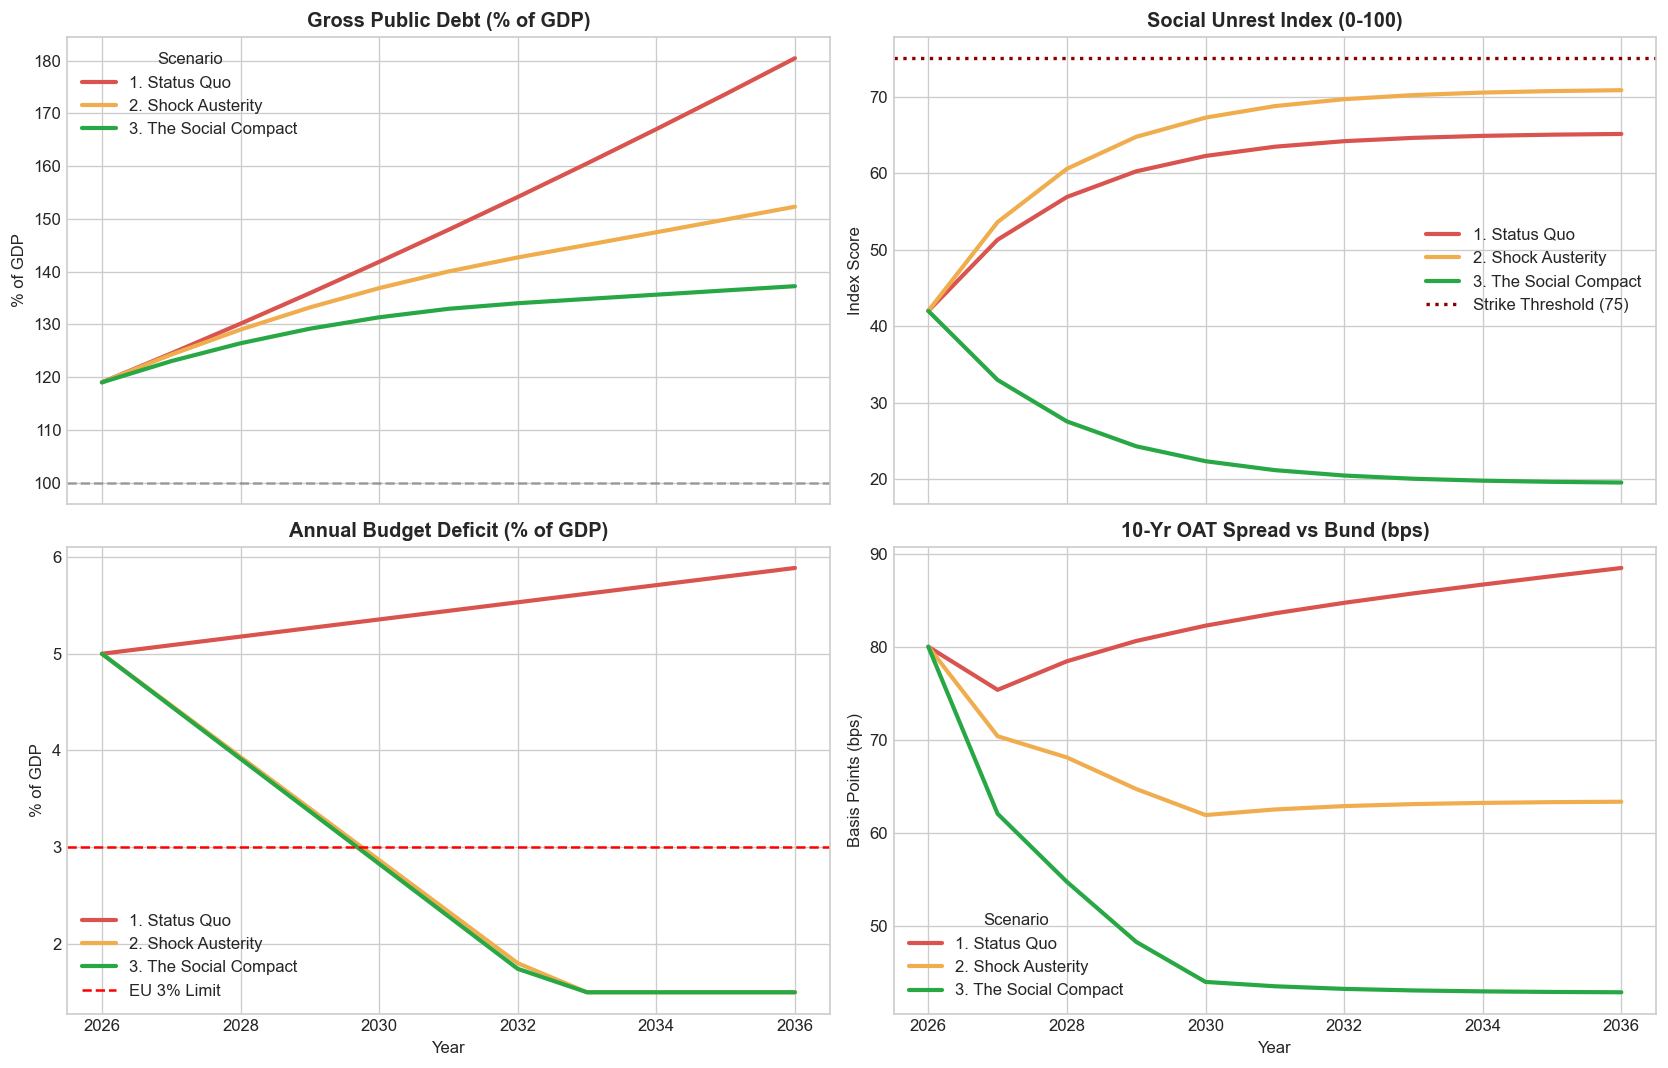

In [3]:
# Cell 3: Execute Scenarios & Visualize the French Trilemma
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Scenario 1: Status Quo (Gridlock & Decrees)
# Doing nothing structural, relying on rule-by-decree, weak economic growth.
df_status_quo = simulate_comprehensive_france(
    scenario_name="1. Status Quo",
    admin_savings_bn=5.0,
    hospital_reinvest_bn=0.0,
    net_immigration_economic_impact=0.0,
    geopolitical_shock=False,
    use_article_49_3=True,
    union_pact=False
)

# Scenario 2: Shock Austerity (Aggressive cuts without consensus)
# Slashing the budget bluntly, failing to integrate labor, bypassing parliament.
df_austerity = simulate_comprehensive_france(
    scenario_name="2. Shock Austerity",
    admin_savings_bn=28.0,
    hospital_reinvest_bn=0.0,
    net_immigration_economic_impact=-2.0, # Poor integration drags on economy
    geopolitical_shock=False,
    use_article_49_3=True,
    union_pact=False
)

# Scenario 3: The Social Compact (Targeted consolidation + growth)
# Smart administrative cuts, hospital reinvestment, labor integration, and negotiated union pacts.
df_compact = simulate_comprehensive_france(
    scenario_name="3. The Social Compact",
    admin_savings_bn=25.0,
    hospital_reinvest_bn=6.0,
    net_immigration_economic_impact=3.0, # Successful integration expands active tax base
    geopolitical_shock=False,
    use_article_49_3=False,
    union_pact=True
)

# Combine all scenarios into one DataFrame
df_all = pd.concat([df_status_quo, df_austerity, df_compact], ignore_index=True)

# ----------------- Visualizing the Results -----------------
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=True)
colors = {'1. Status Quo': '#d9534f', '2. Shock Austerity': '#f0ad4e', '3. The Social Compact': '#28a745'}

# 1. Debt-to-GDP Trajectory
sns.lineplot(data=df_all, x='Year', y='Debt_GDP', hue='Scenario', palette=colors, lw=2.5, ax=axes[0, 0])
axes[0, 0].set_title("Gross Public Debt (% of GDP)", fontweight='bold')
axes[0, 0].axhline(100.0, color='gray', linestyle='--', alpha=0.7)
axes[0, 0].set_ylabel("% of GDP")

# 2. Social Unrest Index
sns.lineplot(data=df_all, x='Year', y='Unrest_Index', hue='Scenario', palette=colors, lw=2.5, ax=axes[0, 1])
axes[0, 1].axhline(75.0, color='darkred', linestyle=':', lw=2, label='Strike Threshold (75)')
axes[0, 1].set_title("Social Unrest Index (0-100)", fontweight='bold')
axes[0, 1].set_ylabel("Index Score")
axes[0, 1].legend()

# 3. Budget Deficit
sns.lineplot(data=df_all, x='Year', y='Deficit_GDP', hue='Scenario', palette=colors, lw=2.5, ax=axes[1, 0])
axes[1, 0].axhline(3.0, color='red', linestyle='--', label='EU 3% Limit')
axes[1, 0].set_title("Annual Budget Deficit (% of GDP)", fontweight='bold')
axes[1, 0].set_ylabel("% of GDP")
axes[1, 0].legend()

# 4. Financial Markets (OAT Spread)
sns.lineplot(data=df_all, x='Year', y='OAT_Spread', hue='Scenario', palette=colors, lw=2.5, ax=axes[1, 1])
axes[1, 1].set_title("10-Yr OAT Spread vs Bund (bps)", fontweight='bold')
axes[1, 1].set_ylabel("Basis Points (bps)")

plt.tight_layout()
plt.show()